# Chapitre 4 - Exercices 4.6 à 4.10

Ce notebook traite cinq exercices sur **construire ou acheter**, les **benchmarks publics**
et la **conception d'un pipeline d'évaluation** :

- **4.6** : le point mort entre API et auto-hébergement (calcul analytique + vérification) ;
- **4.7** : agréger un classement à la main, et choisir des benchmarks peu redondants (calcul) ;
- **4.8** : détecter la contamination par n-grammes et par perplexité (mini-lab) ;
- **4.9** : construire et désamorcer un paradoxe de Simpson (calcul + raisonnement) ;
- **4.10** : combien d'exemples pour comparer deux prompts ? (calcul + simulation de puissance).

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score, roc_curve
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
rng = np.random.default_rng(0)

## Exercice 4.6 : Le point mort entre API et auto-hébergement

**Énoncé.** Une application traite des requêtes de 2 000 tokens d'entrée et 300 tokens de
sortie.

- API : 2,50 $ par million de tokens d'entrée, 10 $ par million de tokens de sortie.
- Auto-hébergement : un GPU loué 3 $/h, qui traite en moyenne 6 000 tokens/s (entrée et sortie
  confondues, lots remplis) quand il est occupé ; taux d'utilisation moyen $u = 40\,\%$ ; coût
  fixe d'ingénierie et d'exploitation $F = 12\,000$ $/mois ; 730 heures par mois.

1. Calculer le coût API par requête $a$, le coût marginal auto-hébergé $m$ et le point mort $N^*$.
   Vérifier qu'un seul GPU suffit au point mort.
2. Même question si l'utilisation tombe à $u = 10\,\%$ (trafic très irrégulier).
3. Les prix des API baissent de 50 % par an. Pour 3 millions de requêtes par mois, au bout de
   combien de temps l'auto-hébergement cesse-t-il d'être rentable ?
4. Citer deux raisons de s'auto-héberger malgré un coût supérieur, et deux raisons inverses.

**Rappels.** Section *API cost versus engineering cost* et cours 3, section 5 :
$C_{API} = aN$ ; $C_{auto} = F + 730\,h\,\lceil N t / (D u \cdot 3600 \cdot 730)\rceil$ avec
$t$ le nombre de tokens par requête ; tant qu'un GPU suffit, $N^*_1 = (F + 730h)/a$ ; à grande
échelle, avec le coût marginal $m = h\,t/(3600\,D\,u)$, $N^*_\infty \approx F/(a - m)$.

**Solution.**

*1.* $a = (2000 \times 2{,}5 + 300 \times 10)/10^6 = 0{,}008$ $ par requête.
$m = 3 \times 2300 / (3600 \times 6000 \times 0{,}4) \approx 0{,}0008$ $ par requête.
Avec un seul GPU, $N^*_1 = (12\,000 + 730 \times 3)/0{,}008 = 14\,190/0{,}008 \approx 1{,}77$ million
de requêtes par mois. Capacité d'un GPU : $6000 \times 0{,}4 \times 3600 \times 730 / 2300 \approx 2{,}74$
millions de requêtes par mois : **un GPU suffit**, le régime « petit volume » s'applique.

*2.* Avec $u = 0{,}1$ : $m \approx 0{,}0032$ $ et la capacité d'un GPU tombe à 0,69 million de
requêtes, bien en dessous de $N^*_1$ : on est dans le régime à plusieurs GPU, où
$N^*_\infty \approx 12\,000/(0{,}008 - 0{,}0032) \approx 2{,}5$ millions. Le calcul numérique (marches
comprises) donne un peu plus, vers 2,6 millions : le point mort recule de près de 50 %.

In [2]:
t = 2300
a = c4.api_cost(1, 2000, 300, 2.5, 10.0)
f_api = lambda n: c4.api_cost(n, 2000, 300, 2.5, 10.0)
rows = []
for u in [0.4, 0.1]:
    f_self = lambda n, u=u: c4.selfhost_cost(n, t, gpu_hour=3.0, gpu_tokens_per_s=6000, utilization=u, fixed_monthly=12_000)
    m = 3.0 * t / (3600 * 6000 * u)
    cap = 6000 * u * 3600 * 730 / t
    rows.append(dict(u=u, a=a, m=m, capacite_1_gpu=cap, N1_un_gpu=(12_000 + 730 * 3) / a,
                     Ninf_grande_echelle=12_000 / (a - m), numerique=c4.breakeven(f_api, f_self, 1e3, 1e9)))
pd.DataFrame(rows).set_index("u").round(5)

,a,m,capacite_1_gpu,N1_un_gpu,Ninf_grande_echelle,numerique
u,,,,,,
0.4,0.008,0.00080,2.742261e+06,1773750.0,1.666345e+06,1.777512e+06
0.1,0.008,0.00319,6.855652e+05,1773750.0,2.497110e+06,2.599284e+06


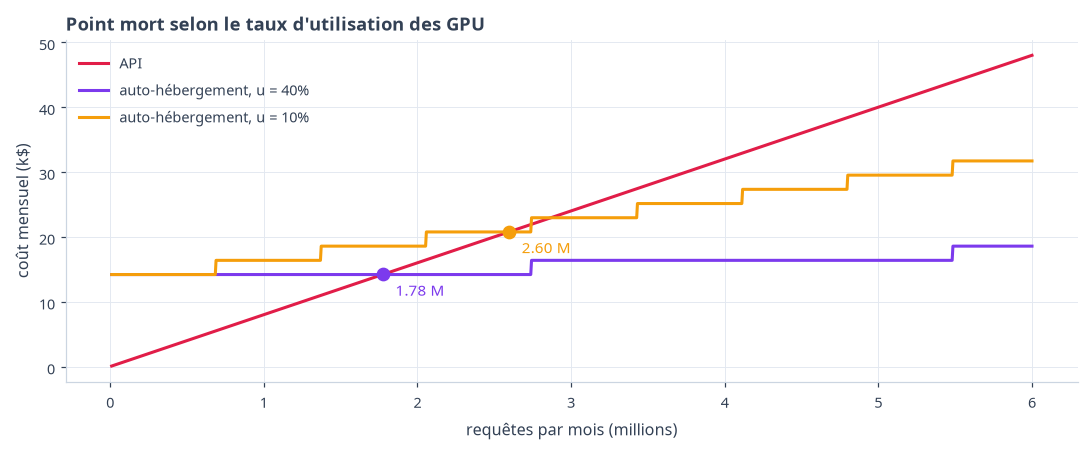

In [3]:
N = np.linspace(1e4, 6e6, 1200)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(N / 1e6, f_api(N) / 1e3, color=ROSE, label="API")
for u, c in [(0.4, VIOLET), (0.1, AMBER)]:
    f_self = lambda n, u=u: c4.selfhost_cost(n, t, gpu_hour=3.0, gpu_tokens_per_s=6000, utilization=u, fixed_monthly=12_000)
    ax.plot(N / 1e6, f_self(N) / 1e3, color=c, label=f"auto-hébergement, u = {u:.0%}")
    be = c4.breakeven(f_api, f_self, 1e3, 1e9)
    ax.plot(be / 1e6, f_api(be) / 1e3, "o", color=c, ms=8)
    ax.annotate(f"{be/1e6:.2f} M", (be / 1e6, f_api(be) / 1e3), xytext=(8, -14), textcoords="offset points", color=c)
ax.set_xlabel("requêtes par mois (millions)"); ax.set_ylabel("coût mensuel (k$)")
ax.set_title("Point mort selon le taux d'utilisation des GPU"); ax.legend()
plt.tight_layout(); plt.show()

Les marches de la courbe à 10 % d'utilisation correspondent à l'ajout d'un GPU : chaque GPU
mal utilisé coûte son prix plein.

*3.* Après $k$ années, $a_k = 0{,}008 \times 0{,}5^k$. Pour $N = 3$ M de requêtes avec $u = 0{,}4$,
il faut 2 GPU : $C_{auto} = 12\,000 + 2 \times 2190 = 16\,380$ $. L'API coûte $24\,000 \times 0{,}5^k$ $.
L'auto-hébergement cesse d'être rentable quand $24\,000 \times 0{,}5^k < 16\,380$, soit
$k > \log_2(24\,000/16\,380) \approx 0{,}55$ an, **environ 7 mois**.

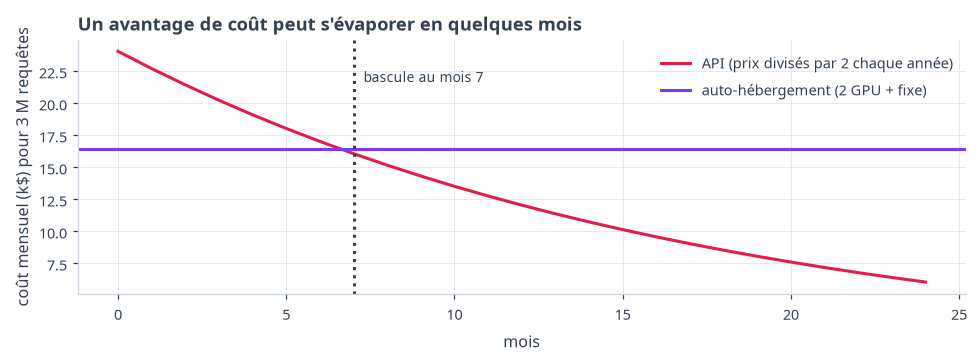

In [4]:
months = np.arange(0, 25)
api_m = f_api(3e6) * 0.5 ** (months / 12)
self_m = c4.selfhost_cost(3e6, t, gpu_hour=3.0, gpu_tokens_per_s=6000, utilization=0.4, fixed_monthly=12_000)
k = months[np.argmax(api_m < self_m)]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(months, api_m / 1e3, color=ROSE, label="API (prix divisés par 2 chaque année)")
ax.axhline(self_m / 1e3, color=VIOLET, label="auto-hébergement (2 GPU + fixe)")
ax.axvline(k, color=SLATE, ls=":"); ax.text(k + 0.3, api_m.max() / 1e3 * 0.9, f"bascule au mois {k}", fontsize=9)
ax.set_xlabel("mois"); ax.set_ylabel("coût mensuel (k$) pour 3 M requêtes"); ax.legend()
ax.set_title("Un avantage de coût peut s'évaporer en quelques mois")
plt.tight_layout(); plt.show()

*4.* Pour l'auto-hébergement malgré le coût : la **confidentialité** (données qui ne doivent pas
sortir), le **contrôle** (figer une version, pas de changement de modèle non annoncé, accès aux
logprobs et à l'affinage). Pour l'API malgré le coût : la **performance** (les meilleurs modèles
sont fermés), l'**absence d'équipe d'infrastructure** et la vitesse de mise sur le marché
(fonctionnalités prêtes : passage à l'échelle, appels de fonctions).

> **À retenir.** Le point mort ($(F + 730h)/a$ avec un GPU, $F/(a-m)$ à grande échelle) est très sensible à l'utilisation
> des GPU et à l'évolution des prix des API : refaites le calcul régulièrement, et ne décidez
> pas sur le coût seul.

## Exercice 4.7 : Agréger un classement, choisir des benchmarks peu redondants

**Énoncé.** Quatre modèles sont évalués sur trois benchmarks (scores en %) :

| | maths | connaissances | véracité |
|---|---|---|---|
| M1 | 90 | 60 | 50 |
| M2 | 70 | 70 | 62 |
| M3 | 55 | 80 | 58 |
| M4 | 60 | 72 | 61 |

1. Classer les modèles par moyenne brute, puis par taux de victoire moyen (HELM). Commenter.
2. Classer par moyenne des z-scores. Pourquoi M1 est-il favorisé par la moyenne brute ?
3. Avec la matrice de corrélation du tableau 4-5 (6 benchmarks de l'Open LLM Leaderboard), on
   ne peut garder que 3 benchmarks. Lesquels garder pour maximiser le nombre effectif
   $B_{\text{eff}} = (\sum\lambda)^2/\sum\lambda^2$ ?

**Rappels.** Section *Benchmark selection and aggregation* et cours 3, sections 6 et 7 :
moyenne brute, taux de victoire moyen
$\text{MWR}_i = \frac1B\sum_b \frac{\#\{j: s_{ib} > s_{jb}\}}{n-1}$, z-scores, nombre effectif
de benchmarks à partir des valeurs propres de la matrice de corrélation.

**Solution.** *1.* Moyennes : M1 = 66,7 ; M2 = 67,3 ; M3 = 64,3 ; M4 = 64,3. Classement : M2,
M1, puis M3 et M4 ex aequo.
Victoires par benchmark (sur 3 adversaires) : maths M1 3, M2 2, M4 1, M3 0 ; connaissances
M3 3, M4 2, M2 1, M1 0 ; véracité M2 3, M4 2, M3 1, M1 0. D'où
$\text{MWR} = $ M1 : 1/3 ; M2 : 2/3 ; M3 : 4/9 ; M4 : 5/9. Classement : **M2, M4, M3, M1**.
M1 passe de 2e à dernier : il ne gagne qu'un benchmark, mais avec une avance énorme que la
moyenne récompense et que le taux de victoire ignore (seul l'ordre compte).

*2.* La moyenne brute pèse implicitement chaque benchmark par sa dispersion : les maths
s'étalent de 55 à 90 (écart-type élevé), donc l'avance de M1 y vaut beaucoup de points. Les
z-scores mettent chaque benchmark à la même échelle.

In [5]:
s = pd.DataFrame({"maths": [90, 70, 55, 60], "connaissances": [60, 70, 80, 72], "véracité": [50, 62, 58, 61]},
                 index=["M1", "M2", "M3", "M4"])
agg = pd.DataFrame({"moyenne": s.mean(axis=1), "taux de victoire": c4.mean_win_rate(s), "z-score": c4.zscore_mean(s)})
ranks = agg.rank(ascending=False, method="min").astype(int).add_prefix("rang ")
print("écarts-types par benchmark :", s.std(ddof=0).round(1).to_dict())
pd.concat([agg.round(3), ranks], axis=1)

écarts-types par benchmark : {'maths': 13.4, 'connaissances': 7.1, 'véracité': 4.7}


,moyenne,taux de victoire,z-score,rang moyenne,rang taux de victoire,rang z-score
M1,66.667,0.333,-0.511,2,4,4
M2,67.333,0.667,0.308,1,1,1
M3,64.333,0.444,0.120,3,3,2
M4,64.333,0.556,0.083,3,2,3


Les trois agrégations placent M2 en tête (il est bon partout), mais divergent sur M1 et M4 :
le choix de l'agrégation est un choix de **valeurs** (préfère-t-on un spécialiste brillant ou
un généraliste régulier ?).

*3.* On énumère les $\binom63 = 20$ sous-ensembles et on calcule $B_{\text{eff}}$ de chaque
sous-matrice de corrélation.

meilleur trio : ('HellaSwag', 'TruthfulQA', 'GSM-8K') -> B_eff = 2.19
pire trio     : ('ARC-C', 'MMLU', 'WinoGrande') -> B_eff = 1.17
les 6 benchmarks : B_eff = 1.93


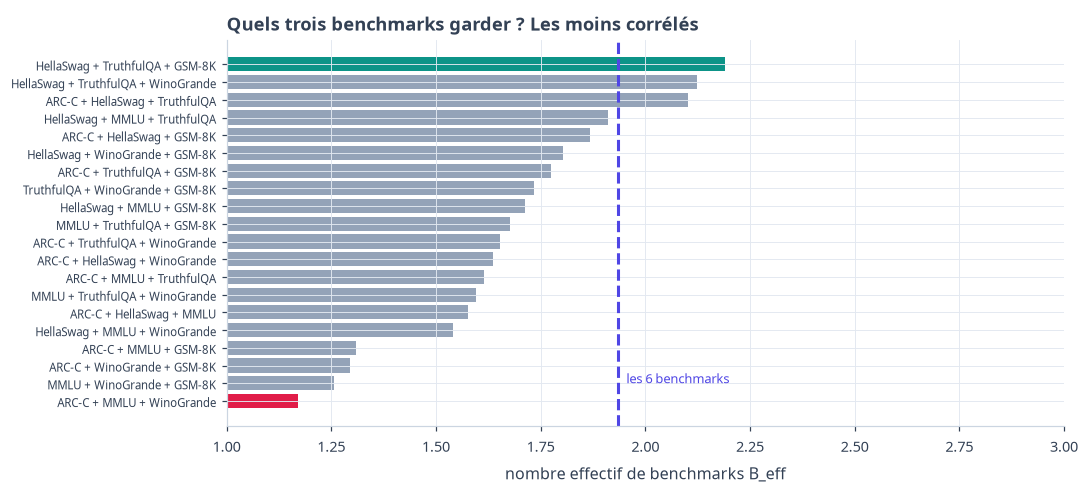

In [6]:
C = c4.HF_CORR
def b_eff(sub):
    lam = np.linalg.eigvalsh(C.loc[list(sub), list(sub)].values)
    return lam.sum() ** 2 / (lam**2).sum()
subs = sorted(((b_eff(sb), sb) for sb in combinations(C.columns, 3)), reverse=True)
best, worst = subs[0], subs[-1]
print(f"meilleur trio : {best[1]} -> B_eff = {best[0]:.2f}")
print(f"pire trio     : {worst[1]} -> B_eff = {worst[0]:.2f}")
print(f"les 6 benchmarks : B_eff = {b_eff(C.columns):.2f}")

fig, ax = plt.subplots(figsize=(10, 4.6))
vals = [v for v, _ in subs]
labels = [" + ".join(sb) for _, sb in subs]
ax.barh(range(len(subs))[::-1], vals, color=[TEAL if i == 0 else (ROSE if i == len(subs) - 1 else GRAY) for i in range(len(subs))])
ax.set_yticks(range(len(subs))[::-1], labels, fontsize=7.5)
ax.axvline(b_eff(C.columns), color=INDIGO, ls="--"); ax.text(b_eff(C.columns) + 0.02, 1, "les 6 benchmarks", color=INDIGO, fontsize=8.5)
ax.set_xlabel("nombre effectif de benchmarks B_eff"); ax.set_xlim(1, 3)
ax.set_title("Quels trois benchmarks garder ? Les moins corrélés")
plt.tight_layout(); plt.show()

Le meilleur trio associe des benchmarks peu corrélés entre eux (HellaSwag et TruthfulQA, plus
un représentant du bloc raisonnement) et atteint un $B_{\text{eff}}$ proche de celui des six
benchmarks réunis : on garde l'essentiel de l'information pour moitié moins de calcul. Le pire
trio (ARC-C, MMLU, WinoGrande) mesure presque trois fois la même chose.

> **À retenir.** Moyenne brute (sensible aux écarts), taux de victoire (ordre seul) et z-scores
> (échelle commune) traduisent des valeurs différentes. Avant d'agréger, éliminez la redondance :
> quelques benchmarks peu corrélés valent mieux que beaucoup de benchmarks redondants.

## Exercice 4.8 : Détecter la contamination par n-grammes et par perplexité

**Énoncé.**

1. *N-grammes.* Un corpus d'entraînement contient, parmi d'autres textes, 4 questions d'un
   benchmark recopiées mot pour mot et 4 questions légèrement modifiées (un mot changé tous les
   huit mots environ) ; 4 autres questions sont absentes. Pour $n \in \{4, 8, 13, 20\}$ (en
   tokens Qwen), on déclare « sale » un exemple dont au moins un n-gramme figure dans le corpus.
   Calculer précision et rappel de la détection des exemples **vus** (copiés ou modifiés).
2. *Perplexité.* Calculer la perplexité de Qwen 0.5B sur 8 phrases célèbres et 8 phrases
   nouvelles de style comparable ; mesurer l'aire sous la courbe ROC d'un détecteur « perplexité
   basse = vu ».
3. Discuter les limites des deux méthodes.

**Rappels.** Section *Data contamination with public benchmarks* : un recouvrement de
13 tokens signale un exemple sale (précis, mais exige les données d'entraînement) ; une
perplexité anormalement basse suggère un texte déjà vu (moins précis, n'exige que le modèle).

**Solution.** *1.* On tokenise avec le tokenizer de Qwen et on construit l'ensemble des
n-grammes du corpus.

In [7]:
tok, _ = llm.load(llm.SMALL)
questions = [
    "Quelle est la somme des angles intérieurs d'un hexagone régulier exprimée en degrés ?",
    "Un cycliste parcourt 45 kilomètres en une heure et demie ; quelle est sa vitesse moyenne ?",
    "Si un article coûte 80 euros après une remise de 20 pour cent, quel était son prix initial ?",
    "Combien de nombres premiers sont strictement compris entre 10 et 30 inclusivement ?",
    "Quelle est la probabilité de tirer un as dans un jeu complet de 52 cartes bien mélangé ?",
    "Un réservoir se remplit en 6 heures avec un robinet et en 3 heures avec un autre ; combien avec les deux ?",
    "Quel est le plus petit multiple commun de 12, 18 et 30 parmi les entiers positifs ?",
    "Une échelle de 5 mètres est posée contre un mur à 3 mètres de sa base ; à quelle hauteur touche-t-elle ?",
    "Combien de diagonales possède un polygone convexe à dix côtés distincts ?",
    "Quelle est la moyenne des cinq premiers entiers naturels impairs strictement positifs ?",
    "Un capital de 1000 euros placé à 5 pour cent par an pendant deux ans rapporte combien en intérêts composés ?",
    "Quelle est l'aire d'un disque dont le diamètre mesure exactement 10 centimètres ?",
]
statut = ["copiée"] * 4 + ["modifiée"] * 4 + ["absente"] * 4
def modify(q, rng):
    w = q.split()
    for i in range(3, len(w), 8):
        w[i] = {"est": "était", "un": "le", "de": "du", "la": "cette"}.get(w[i], w[i] + "s")
    return " ".join(w)
r = np.random.default_rng(0)
corpus = ("Forum d'entraide en mathématiques. " + " ".join(questions[:4]) + " Corrigés détaillés ci-dessous. "
          + " ".join(modify(q, r) for q in questions[4:8]) + " Fin de la page.")
corpus_ids = tok(corpus)["input_ids"]
rows = []
for n in [4, 8, 13, 20]:
    grams = c4.ngrams([str(i) for i in corpus_ids], n)
    for q, st in zip(questions, statut):
        qg = c4.ngrams([str(i) for i in tok(" " + q)["input_ids"]], n)
        frac = len(qg & grams) / max(len(qg), 1)
        rows.append(dict(n=n, statut=st, recouvrement=frac, sale=frac > 0))
det = pd.DataFrame(rows)
det["vue"] = det.statut != "absente"
pr = det.groupby("n").apply(lambda g: pd.Series({
    "précision": (g.sale & g.vue).sum() / max(g.sale.sum(), 1), "rappel": (g.sale & g.vue).sum() / g.vue.sum(),
    "rappel copiées": g[g.statut == "copiée"].sale.mean(), "rappel modifiées": g[g.statut == "modifiée"].sale.mean()}),
    include_groups=False)
pr.round(2)

,précision,rappel,rappel copiées,rappel modifiées
n,,,,
4,0.89,1.00,1.0,1.00
8,1.00,1.00,1.0,1.00
13,1.00,0.62,1.0,0.25
20,1.00,0.50,1.0,0.00


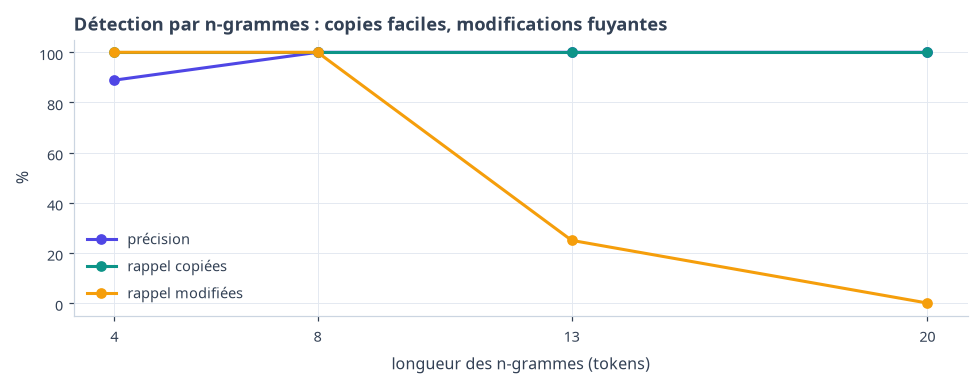

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for col, c in [("précision", INDIGO), ("rappel copiées", TEAL), ("rappel modifiées", AMBER)]:
    ax.plot(pr.index, pr[col] * 100, "o-", color=c, label=col)
ax.set_xlabel("longueur des n-grammes (tokens)"); ax.set_ylabel("%"); ax.set_ylim(-5, 105)
ax.set_xticks(pr.index); ax.legend(); ax.set_title("Détection par n-grammes : copies faciles, modifications fuyantes")
plt.tight_layout(); plt.show()

Les copies exactes sont détectées pour tout $n$. Les questions modifiées (un mot sur huit)
échappent aux longs n-grammes : avec $n = 13$, la plupart passent entre les mailles, et
toutes avec $n = 20$, alors que le modèle a bel et bien vu une version quasi identique. Avec $n = 4$, on les
rattrape, au risque de faux positifs sur des expressions banales (« quelle est la »).

*2.* Perplexité sur phrases célèbres et phrases nouvelles.

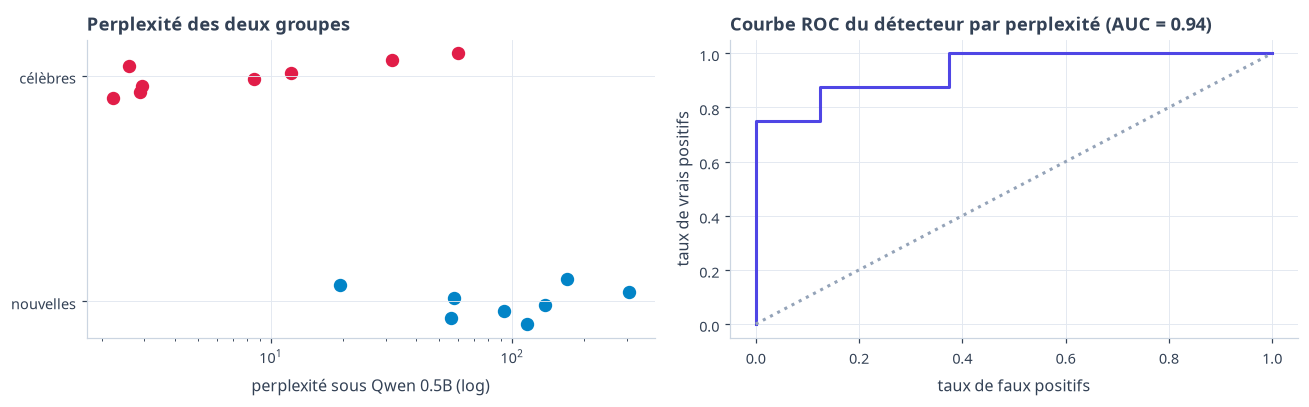

In [9]:
celebres = [
    "It was the best of times, it was the worst of times, it was the age of wisdom, it was the age of foolishness.",
    "It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife.",
    "Four score and seven years ago our fathers brought forth on this continent, a new nation, conceived in Liberty.",
    "Happy families are all alike; every unhappy family is unhappy in its own way.",
    "In the beginning God created the heaven and the earth.",
    "The quick brown fox jumps over the lazy dog.",
    "Longtemps, je me suis couché de bonne heure.",
    "Je pense, donc je suis.",
]
nouvelles = [
    "It was the coldest of mornings, the harbour silent under a grey and patient fog that hid the boats.",
    "Every gardener in the village knows that tomatoes planted too early will sulk until the summer arrives.",
    "Three weeks after the storm, the old bridge was finally reopened to cyclists and slow delivery vans.",
    "Small cafés tend to close on Mondays, which is precisely when tired travellers need them most.",
    "The library moved its rare maps to the basement after the roof began to leak.",
    "A curious otter stole the fisherman's sandwich and vanished under the pier.",
    "Ce matin, le boulanger a oublié d'allumer son four avant six heures.",
    "Les mouettes ont envahi la terrasse du port dès midi.",
]
ppl = pd.DataFrame(dict(texte=celebres + nouvelles, vu=[1] * 8 + [0] * 8))
ppl["perplexite"] = [llm.perplexity(t_, llm.SMALL) for t_ in ppl.texte]
auc = roc_auc_score(ppl.vu, -np.log(ppl.perplexite))
fpr, tpr, _ = roc_curve(ppl.vu, -np.log(ppl.perplexite))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for v, c, lab in [(1, ROSE, "célèbres (probablement vues)"), (0, SKY, "nouvelles")]:
    pv = ppl[ppl.vu == v].perplexite
    axes[0].scatter(pv, np.full(len(pv), v) + np.linspace(-0.1, 0.1, len(pv)), color=c, s=60, label=lab)
axes[0].set_xscale("log"); axes[0].set_yticks([0, 1], ["nouvelles", "célèbres"])
axes[0].set_xlabel("perplexité sous Qwen 0.5B (log)"); axes[0].set_title("Perplexité des deux groupes")
axes[1].plot(fpr, tpr, color=INDIGO, drawstyle="steps-post"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls=":")
axes[1].set_xlabel("taux de faux positifs"); axes[1].set_ylabel("taux de vrais positifs")
axes[1].set_title(f"Courbe ROC du détecteur par perplexité (AUC = {auc:.2f})")
finish(fig)

Les phrases célèbres ont une perplexité nettement plus basse, et l'AUC est élevée sur ce petit
échantillon. Le détecteur est pourtant imparfait par nature : une phrase très courte et
formulaïque (« Je pense, donc je suis ») ou au contraire une phrase nouvelle très banale peut
brouiller la frontière.

*3.* **Limites.** N-grammes : il faut les données d'entraînement (rarement publiées), la
comparaison est coûteuse à grande échelle, et la paraphrase ou la traduction échappent à la
détection. Perplexité : un texte banal a une perplexité basse sans contamination (faux positif),
un texte vu une seule fois peut ne pas être mémorisé (faux négatif), et le seuil dépend du
modèle, de la langue et du domaine. En pratique, on combine les deux et on rapporte le score sur
la partie propre du benchmark.

> **À retenir.** Le recouvrement de n-grammes est précis pour les copies mais aveugle aux
> reformulations dès que $n$ est grand ; la perplexité détecte la mémorisation sans accès aux
> données mais confond « banal » et « vu ».

## Exercice 4.9 : Construire et désamorcer un paradoxe de Simpson

**Énoncé.** On compare deux versions d'un prompt sur des requêtes **courtes** (faciles) et
**longues** (difficiles). Faute de temps, chaque version a été évaluée sur un échantillon
différent :

| | courtes | longues |
|---|---|---|
| prompt v1 | 180 / 200 | 30 / 100 |
| prompt v2 | 95 / 100 | 70 / 200 |

1. Calculer les taux par tranche et globaux. Quel prompt gagne ?
2. Écrire le taux global comme une moyenne pondérée et expliquer le paradoxe.
3. En production, 60 % des requêtes sont courtes. Quel prompt choisir ?
4. Quelle procédure d'évaluation aurait évité le problème ?

**Rappels.** Section *Annotate evaluation data* (tableau 4-6) et cours 4, section 5 : un
score global compare des **mélanges** de tranches ; on le corrige en pondérant par la
distribution de production, $\text{score}_{\text{prod}} = \sum_g \pi_g\,\text{score}_g$.

**Solution.** *1.* v1 : 90 % (courtes), 30 % (longues), 210/300 = 70 % au global. v2 : 95 %,
35 %, 165/300 = 55 % au global. **v2 gagne dans chaque tranche, mais perd au global.**

*2.* $\text{global} = \pi\,s_{\text{courtes}} + (1-\pi)\,s_{\text{longues}}$ où $\pi$ est la
part des requêtes courtes **dans l'échantillon de cette version** : $\pi_{v1} = 2/3$,
$\pi_{v2} = 1/3$. v2 a reçu deux fois plus de requêtes difficiles : son global est tiré vers son
score sur les longues. Le paradoxe apparaît quand l'écart de mélange l'emporte sur l'écart de
performance : ici $(\pi_{v1} - \pi_{v2})(s_c - s_l) \approx \frac13 \times 60 = 20$ points de
« bonus de mélange » pour v1, contre 5 points d'avantage réel pour v2 dans chaque tranche.

*3.* À mélange de production ($\pi = 0{,}6$) : v1 = $0{,}6 \times 0{,}90 + 0{,}4 \times 0{,}30 = 66\,\%$ ;
v2 = $0{,}6 \times 0{,}95 + 0{,}4 \times 0{,}35 = 71\,\%$. **On choisit v2.**

paradoxe de Simpson : True


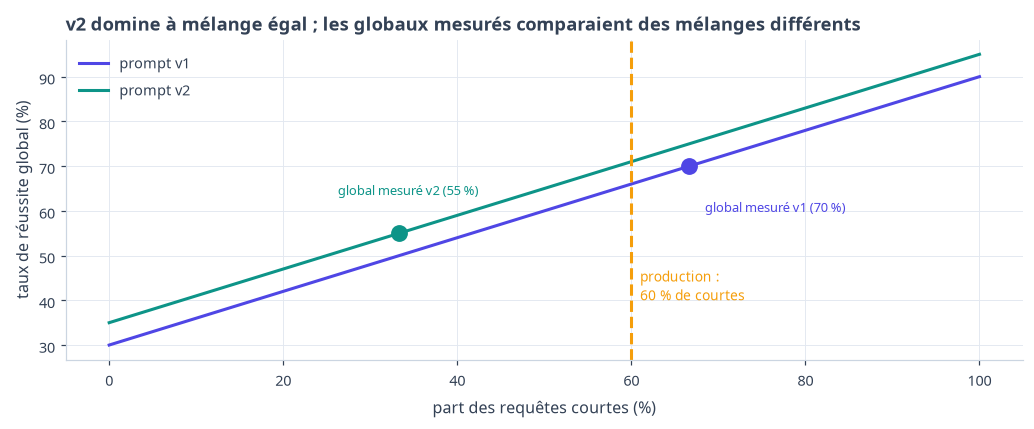

,courtes,longues,global
prompt v1,90.0,30.0,70.0
prompt v2,95.0,35.0,55.0


In [10]:
counts = {"prompt v1": {"courtes": (180, 200), "longues": (30, 100)},
          "prompt v2": {"courtes": (95, 100), "longues": (70, 200)}}
tab = c4.simpson_table(counts)
print("paradoxe de Simpson :", c4.is_simpson(counts))
pis = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(9.5, 4))
for mname, c in [("prompt v1", INDIGO), ("prompt v2", TEAL)]:
    ax.plot(pis * 100, (pis * tab.loc[mname, "courtes"] + (1 - pis) * tab.loc[mname, "longues"]) * 100, color=c, label=mname)
ax.plot(200 / 300 * 100, tab.loc["prompt v1", "global"] * 100, "o", color=INDIGO, ms=10)
ax.plot(100 / 300 * 100, tab.loc["prompt v2", "global"] * 100, "o", color=TEAL, ms=10)
ax.axvline(60, color=AMBER, ls="--"); ax.text(61, 40, "production :\n60 % de courtes", color=AMBER, fontsize=9)
ax.annotate("global mesuré v1 (70 %)", (66.7, 70), xytext=(10, -30), textcoords="offset points", fontsize=8.5, color=INDIGO)
ax.annotate("global mesuré v2 (55 %)", (33.3, 55), xytext=(-40, 25), textcoords="offset points", fontsize=8.5, color=TEAL)
ax.set_xlabel("part des requêtes courtes (%)"); ax.set_ylabel("taux de réussite global (%)")
ax.set_title("v2 domine à mélange égal ; les globaux mesurés comparaient des mélanges différents")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
(tab * 100).round(1)

*4.* Évaluer les deux versions **sur le même jeu d'exemples** (évaluation appariée), ou au
minimum avec le même mélange de tranches ; rapporter les scores par tranche et un global
pondéré par la distribution de production.

> **À retenir.** Un paradoxe de Simpson naît quand des systèmes sont évalués sur des mélanges
> différents de tranches de difficulté inégale. Le remède : mêmes exemples, scores par tranche,
> global pondéré par la production.

## Exercice 4.10 : Combien d'exemples pour comparer deux prompts ?

**Énoncé.** Le prompt actuel réussit 80 % des cas ; on espère qu'un nouveau prompt atteigne
85 %.

1. Combien d'exemples faut-il pour détecter cet écart (test bilatéral à 5 %, puissance 80 %) si
   les deux prompts sont évalués sur des jeux **indépendants** ?
2. Même question si les deux prompts sont évalués sur **les mêmes exemples** et ne sont en
   désaccord que sur 10 % d'entre eux.
3. Vérifier par simulation la puissance des deux protocoles en fonction de $n$.
4. Retrouver la règle d'OpenAI « écart divisé par 3, exemples multipliés par 10 ».

**Rappels.** Section *Annotate evaluation data* (tableau 4-7) et cours 4, section 6 :
$n = (z_{1-\alpha/2} + z_{1-\beta})^2\,\sigma^2/\Delta^2$, avec $\sigma^2 = p_1(1-p_1) + p_2(1-p_2)$
en non apparié et $\sigma^2 = d - \Delta^2$ en apparié ($d$ = taux de désaccord).

**Solution.** *1.* $(1{,}96 + 0{,}84)^2 = 7{,}85$ ; $\sigma^2 = 0{,}8 \times 0{,}2 + 0{,}85 \times 0{,}15 = 0{,}2875$ ;
$n = 7{,}85 \times 0{,}2875 / 0{,}05^2 \approx$ **903 exemples par prompt** (1 806 évaluations).

*2.* $\sigma^2 = 0{,}10 - 0{,}0025 = 0{,}0975$ ; $n = 7{,}85 \times 0{,}0975/0{,}0025 \approx$ **306
exemples**, évalués par les deux prompts : trois fois moins d'exemples à annoter. Seuls les
exemples sur lesquels les prompts divergent portent l'information sur leur différence.

*4.* $n \propto 1/\Delta^2$ : diviser $\Delta$ par 3 multiplie $n$ par 9, que la règle arrondit à
10 (car $\sqrt{10} \approx 3{,}16$).

non apparié : 903 exemples par prompt ; apparié : 306 exemples


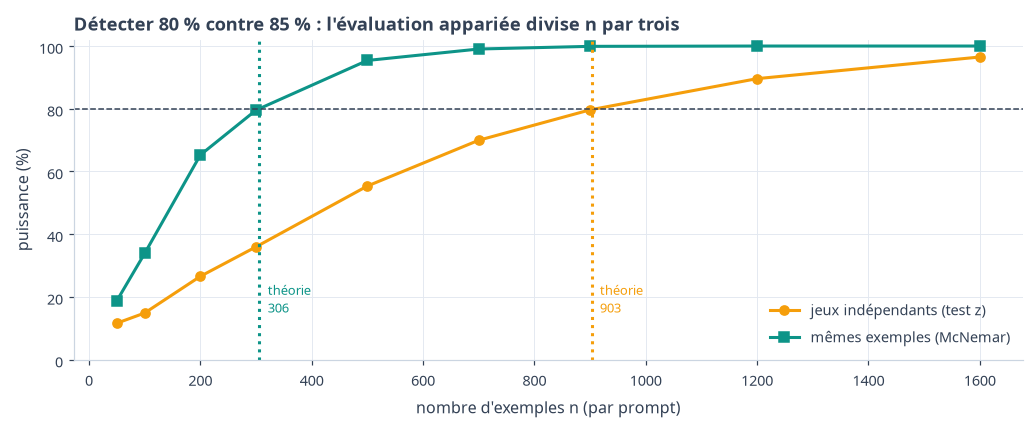

In [11]:
z = (norm.ppf(0.975) + norm.ppf(0.8)) ** 2
n_unp = z * (0.8 * 0.2 + 0.85 * 0.15) / 0.05**2
n_pai = c4.sample_size_two_proportions(0.8, 0.05, paired=True, discordance=0.10)
print(f"non apparié : {n_unp:.0f} exemples par prompt ; apparié : {n_pai:.0f} exemples")

def power_sim(n, paired, reps=2000, rng=np.random.default_rng(0)):
    hits = 0
    for _ in range(reps):
        if paired:
            # loi jointe : P(1,1)=0.775, P(0,1)=0.075, P(1,0)=0.025, P(0,0)=0.125 -> p_a=0.80, p_b=0.85, d=0.10
            cat = rng.choice(4, size=n, p=[0.775, 0.075, 0.025, 0.125])
            n01, n10 = (cat == 1).sum(), (cat == 2).sum()
            stat = (n01 - n10) ** 2 / max(n01 + n10, 1)         # test de McNemar
            hits += stat > 3.84
        else:
            a = rng.random(n) < 0.80; b = rng.random(n) < 0.85
            pa, pb = a.mean(), b.mean(); pbar = (pa + pb) / 2
            se = np.sqrt(2 * pbar * (1 - pbar) / n)
            hits += abs(pb - pa) / se > 1.96
    return hits / reps

ns = [50, 100, 200, 300, 500, 700, 900, 1200, 1600]
pw = pd.DataFrame({"non apparié": [power_sim(n, False) for n in ns], "apparié (McNemar)": [power_sim(n, True) for n in ns]}, index=ns)
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(pw.index, pw["non apparié"] * 100, "o-", color=AMBER, label="jeux indépendants (test z)")
ax.plot(pw.index, pw["apparié (McNemar)"] * 100, "s-", color=TEAL, label="mêmes exemples (McNemar)")
ax.axhline(80, color=SLATE, ls="--", lw=1)
ax.axvline(n_pai, color=TEAL, ls=":"); ax.axvline(n_unp, color=AMBER, ls=":")
ax.text(n_pai + 15, 15, f"théorie\n{n_pai:.0f}", color=TEAL, fontsize=8.5)
ax.text(n_unp + 15, 15, f"théorie\n{n_unp:.0f}", color=AMBER, fontsize=8.5)
ax.set_xlabel("nombre d'exemples n (par prompt)"); ax.set_ylabel("puissance (%)"); ax.set_ylim(0, 102)
ax.set_title("Détecter 80 % contre 85 % : l'évaluation appariée divise n par trois"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [12]:
deltas = np.array([0.30, 0.10, 0.03, 0.01])
regle = pd.DataFrame(dict(écart=[f"{d:.0%}" for d in deltas], n_formule=[c4.sample_size_two_proportions(0.5, d) for d in deltas],
                          n_OpenAI=[10, 100, 1000, 10000]))
regle["rapport avec la ligne précédente"] = regle.n_formule / regle.n_formule.shift(1)
regle.round(1)

,écart,n_formule,n_OpenAI,rapport avec la ligne précédente
0,30%,43.6,10,NaN
1,10%,392.4,100,9.0
2,3%,4360.5,1000,11.1
3,1%,39244.4,10000,9.0


Les simulations retrouvent les seuils théoriques (la puissance franchit 80 % autour de 300
exemples en apparié, 900 en non apparié), et la formule reproduit la pente de la règle
d'OpenAI : un rapport de 9 à 11 entre lignes successives (les écarts du tableau ne sont pas
exactement divisés par 3 à chaque ligne). En valeur absolue, la formule demande environ 4 fois
plus d'exemples qu'OpenAI : les chiffres d'OpenAI correspondent plutôt à l'intervalle de
confiance d'**un seul** score ($n \approx 1/\Delta^2$), sans exigence de puissance.

> **À retenir.** Le nombre d'exemples nécessaire croît en $1/\Delta^2$. Évaluer les deux
> systèmes sur les mêmes exemples (analyse appariée, test de McNemar) réduit fortement ce
> nombre quand les systèmes sont d'accord sur la plupart des cas.

In [13]:
llm.free_gpu()